# MovieLens Recommendation System


## Objective

Compare content-based, user-based collaborative, and hybrid movie recommendation approaches, then evaluate their Top-K ranking quality against a popularity baseline.

## Dataset

The analysis uses MovieLens `ml-latest-small`: 100,836 ratings and 9,742 movies from 610 users, plus genres and user-supplied tags. Download instructions and licensing notes are in `data/README.md`; raw files are not redistributed here.

## Method

The original exploratory analysis and example recommenders are retained. The portfolio version adds a timestamp-aware user-level holdout evaluation with reusable Precision@K, Recall@K, NDCG@K, and HitRate@K functions.


## **Objectives**
* To explore patterns in movie ratings, genres and rating times from a relevant secondary movie dataset as rated by real users.
* To apply collaborative, content-based and hybrid filtering for building multiple types of movie recommendation systems.
* To identify the best recommendation system by asessing the applied methods and test results of recommendation systems.

In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Text and similarity tools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sns.set_style("whitegrid")

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

## **1. Data Understanding and Loading**
The small version of MovieLens dataset is used for making movie recommedations which has over 9000 movies with more than 100,000 ratings tagged with more than 3600 categories by around 600 users. The dataset consists of the following files.

Data Source - https://grouplens.org/datasets/movielens/latest/

* movies.csv - movie ID, movie title and genres
* ratings.csv - user ID, movie ID, rating and timestamp of rating
* tags.csv - user ID, movie ID, tag category and timestamp of tag
* links.csv - movie ID, IMDb ID and TMDB ID

These four data files are loaded and columns are explored to observe that there are missing or duplicate records.

In [ ]:
# Resolve MovieLens files whether Jupyter starts in the repository root or notebooks/.
from pathlib import Path

candidate_roots = [Path("data/ml-latest-small"), Path("../data/ml-latest-small")]
movielens_root = next((path for path in candidate_roots if (path / "ratings.csv").exists()), None)
if movielens_root is None:
    raise FileNotFoundError("Download ml-latest-small into data/ml-latest-small; see data/README.md")

movies_path = movielens_root / "movies.csv"
ratings_path = movielens_root / "ratings.csv"
tags_path = movielens_root / "tags.csv"
links_path = movielens_root / "links.csv"

movies = pd.read_csv(movies_path)
ratings = pd.read_csv(ratings_path)
tags = pd.read_csv(tags_path)
links = pd.read_csv(links_path)


In [3]:
# Preview each dataset
display(movies.head())
display(ratings.head())
display(tags.head())
display(links.head())

# Check column names
print("Movies columns:", movies.columns.tolist())
print("Ratings columns:", ratings.columns.tolist())
print("Tags columns:", tags.columns.tolist())
print("Links columns:", links.columns.tolist())

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


Movies columns: ['movieId', 'title', 'genres']
Ratings columns: ['userId', 'movieId', 'rating', 'timestamp']
Tags columns: ['userId', 'movieId', 'tag', 'timestamp']
Links columns: ['movieId', 'imdbId', 'tmdbId']


## **2. Dataset Preprocessing**

### **2.1 Initial Data Understanding**

In [4]:
# Check dataset structures
print("Movies info:")
movies.info()

print("\nRatings info:")
ratings.info()

print("\nTags info:")
tags.info()

print("\nLinks info:")
links.info()

Movies info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB

Ratings info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

Tags info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   userId     3683 non-nu

In [5]:
# Rating summary
rating_summary = ratings["rating"].describe()

# Unique counts
summary_counts = pd.DataFrame({
    "Dataset": ["Movies", "Ratings", "Tags", "Users in Ratings", "Users in Tags"],
    "Count": [
        movies["movieId"].nunique(),
        len(ratings),
        len(tags),
        ratings["userId"].nunique(),
        tags["userId"].nunique()
    ]
})

display(rating_summary)
display(summary_counts)

count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

,Dataset,Count
0,Movies,9742
1,Ratings,100836
2,Tags,3683
3,Users in Ratings,610
4,Users in Tags,58


### **2.2 Initial Data Quality Check**

In [6]:
# Missing values
missing_summary = pd.DataFrame({
    "Movies": movies.isnull().sum(),
    "Ratings": ratings.isnull().sum(),
    "Tags": tags.isnull().sum(),
    "Links": links.isnull().sum()
})

# Duplicate rows
duplicate_summary = pd.DataFrame({
    "Dataset": ["Movies", "Ratings", "Tags", "Links"],
    "DuplicateRows": [
        movies.duplicated().sum(),
        ratings.duplicated().sum(),
        tags.duplicated().sum(),
        links.duplicated().sum()
    ]
})

display(missing_summary)
display(duplicate_summary)

,Movies,Ratings,Tags,Links
genres,0.0,NaN,NaN,NaN
imdbId,NaN,NaN,NaN,0.0
movieId,0.0,0.0,0.0,0.0
rating,NaN,0.0,NaN,NaN
tag,NaN,NaN,0.0,NaN
timestamp,NaN,0.0,0.0,NaN
title,0.0,NaN,NaN,NaN
tmdbId,NaN,NaN,NaN,8.0
userId,NaN,0.0,0.0,NaN


,Dataset,DuplicateRows
0,Movies,0
1,Ratings,0
2,Tags,0
3,Links,0


In [7]:
# Rating range
rating_min = ratings["rating"].min()
rating_max = ratings["rating"].max()

# Movie ID consistency
ratings_missing_movies = ~ratings["movieId"].isin(movies["movieId"])
tags_missing_movies = ~tags["movieId"].isin(movies["movieId"])

# Data quality table
quality_check = pd.DataFrame({
    "Check": [
        "Minimum Rating",
        "Maximum Rating",
        "Ratings with Missing Movie Metadata",
        "Tags with Missing Movie Metadata",
        "Duplicate User-Movie Ratings"
    ],
    "Value": [
        rating_min,
        rating_max,
        ratings_missing_movies.sum(),
        tags_missing_movies.sum(),
        ratings.duplicated(subset=["userId", "movieId"]).sum()
    ]
})

display(quality_check)

,Check,Value
0,Minimum Rating,0.5
1,Maximum Rating,5.0
2,Ratings with Missing Movie Metadata,0.0
3,Tags with Missing Movie Metadata,0.0
4,Duplicate User-Movie Ratings,0.0


It is observed that movies are rated between 0 and 5 with minimum rating of 0.5 and maximum rating of 5 with no missing or duplicate ratings.

## **3. Data Preparation**

In [8]:
# Convert rating timestamps
ratings["rating_date"] = pd.to_datetime(ratings["timestamp"], unit="s")

# Convert tag timestamps
tags["tag_date"] = pd.to_datetime(tags["timestamp"], unit="s")

# Preview updated data
display(ratings.head())
display(tags.head())

,userId,movieId,rating,timestamp,rating_date
0,1,1,4.0,964982703,2000-07-30 18:45:03
1,1,3,4.0,964981247,2000-07-30 18:20:47
2,1,6,4.0,964982224,2000-07-30 18:37:04
3,1,47,5.0,964983815,2000-07-30 19:03:35
4,1,50,5.0,964982931,2000-07-30 18:48:51


,userId,movieId,tag,timestamp,tag_date
0,2,60756,funny,1445714994,2015-10-24 19:29:54
1,2,60756,Highly quotable,1445714996,2015-10-24 19:29:56
2,2,60756,will ferrell,1445714992,2015-10-24 19:29:52
3,2,89774,Boxing story,1445715207,2015-10-24 19:33:27
4,2,89774,MMA,1445715200,2015-10-24 19:33:20


The rating date and tag date are converted to datetime type as appropriate.

In [9]:
# Extract release year from title
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)")

# Convert year to numeric
movies["year"] = pd.to_numeric(movies["year"], errors="coerce")

# Remove year from clean title
movies["clean_title"] = movies["title"].str.replace(r"\s*\(\d{4}\)", "", regex=True)

# Preview movie data
display(movies.head())
display(movies[["year", "clean_title"]].isnull().sum())

,movieId,title,genres,year,clean_title
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,Toy Story
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995.0,Jumanji
2,3,Grumpier Old Men (1995),Comedy|Romance,1995.0,Grumpier Old Men
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,Waiting to Exhale
4,5,Father of the Bride Part II (1995),Comedy,1995.0,Father of the Bride Part II


year           13
clean_title     0
dtype: int64

The release years of movies are extracted from title where for 13 movies no year was found and from title those years are removed.

In [10]:
# Replace separator with space for text processing
movies["genres_clean"] = movies["genres"].str.replace("|", " ", regex=False)

# Replace missing genre label
movies["genres_clean"] = movies["genres_clean"].replace("(no genres listed)", "")

# Count number of genres
movies["genre_count"] = movies["genres"].apply(lambda x: 0 if x == "(no genres listed)" else len(x.split("|")))

# Preview genre preparation
display(movies[["movieId", "title", "genres", "genres_clean", "genre_count"]].head())

,movieId,title,genres,genres_clean,genre_count
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Adventure Animation Children Comedy Fantasy,5
1,2,Jumanji (1995),Adventure|Children|Fantasy,Adventure Children Fantasy,3
2,3,Grumpier Old Men (1995),Comedy|Romance,Comedy Romance,2
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,Comedy Drama Romance,3
4,5,Father of the Bride Part II (1995),Comedy,Comedy,1


The genres are seperated with space for preprocessing and number of genres for each movie is computed.

## **4. Exploratory Data Analysis**

### **4.1 Rating Distribution**

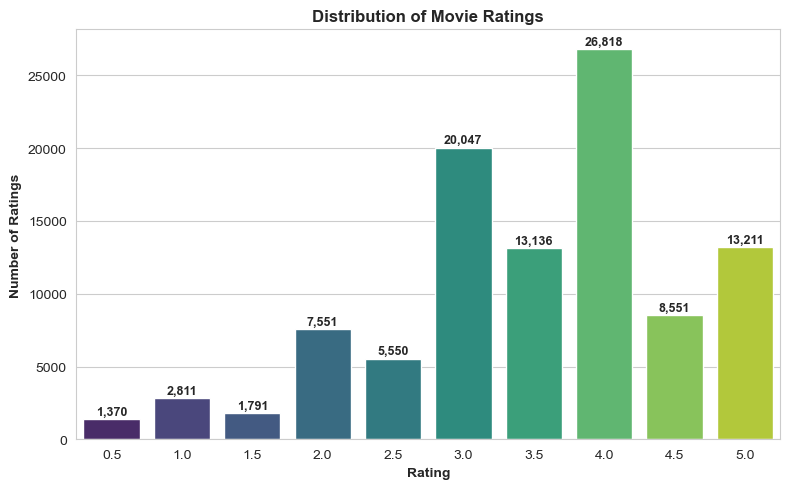

In [11]:
# Rating counts
rating_counts = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="viridis")

# Add data labels
for i, value in enumerate(rating_counts.values):
    ax.text(i, value + 300, f"{value:,}", ha="center", fontsize=9, fontweight="bold")

plt.title("Distribution of Movie Ratings", fontsize=12, fontweight="bold")
plt.xlabel("Rating", fontsize=10, fontweight="bold")
plt.ylabel("Number of Ratings", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

Most movies were rated 4 with a frequency of 26818 and rated 3 for 20047 movies while other ratings are less frequent.

### **4.2 Ratings Over Time**

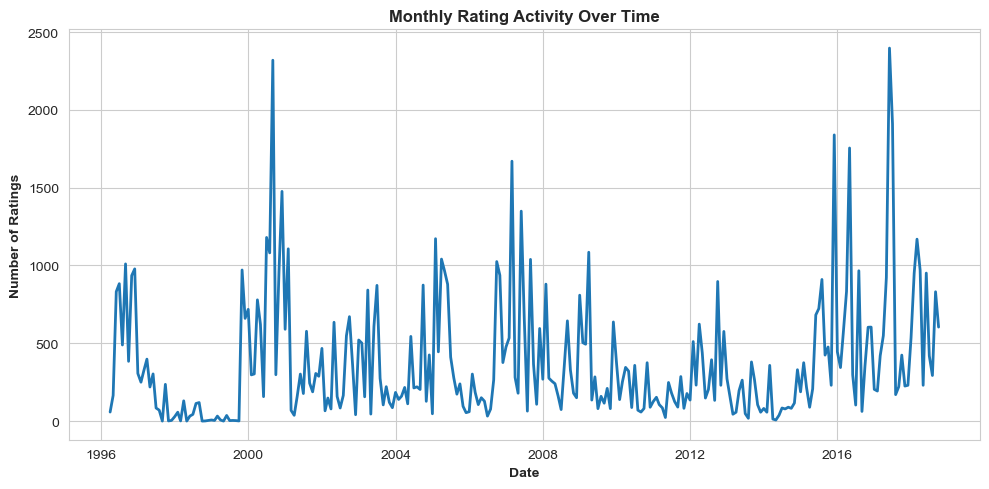

In [12]:
# Monthly rating counts
monthly_ratings = (
    ratings
    .set_index("rating_date")
    .resample("M")
    .size()
    .reset_index(name="rating_count")
)

plt.figure(figsize=(10, 5))

sns.lineplot(data=monthly_ratings, x="rating_date", y="rating_count", linewidth=2)

plt.title("Monthly Rating Activity Over Time", fontsize=12, fontweight="bold")
plt.xlabel("Date", fontsize=10, fontweight="bold")
plt.ylabel("Number of Ratings", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

Rating frequency varies over time with occasional high spikes like in mid 2000s and between years 2016 to 2018 respectively. 

### **4.3 Most Rated Movies**

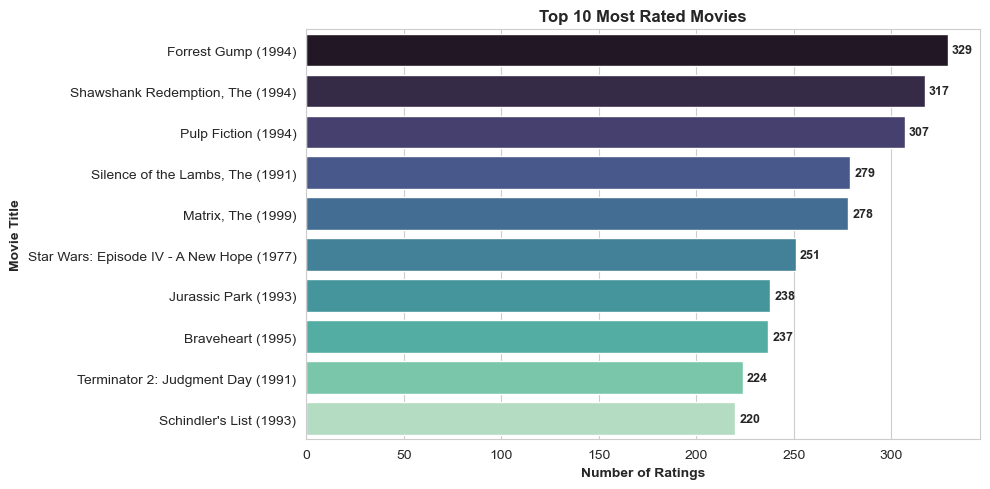

In [13]:
# Most rated movies
movie_rating_counts = (
    ratings
    .groupby("movieId")
    .size()
    .reset_index(name="rating_count")
    .merge(movies[["movieId", "title"]], on="movieId", how="left")
    .sort_values("rating_count", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(data=movie_rating_counts, x="rating_count", y="title", palette="mako")

# Add data labels
for i, value in enumerate(movie_rating_counts["rating_count"]):
    ax.text(value + 2, i, f"{value:,}", va="center", fontsize=9, fontweight="bold")

plt.title("Top 10 Most Rated Movies", fontsize=12, fontweight="bold")
plt.xlabel("Number of Ratings", fontsize=10, fontweight="bold")
plt.ylabel("Movie Title", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

Top 3 highest rated movies belongs to the year 1994 which is followed by The Silence of the Lambs in 1991 and The Matrix in 1999, while ratings of other moviews in the top 10 list are relatively low.   

### **4.4 Top Genres**

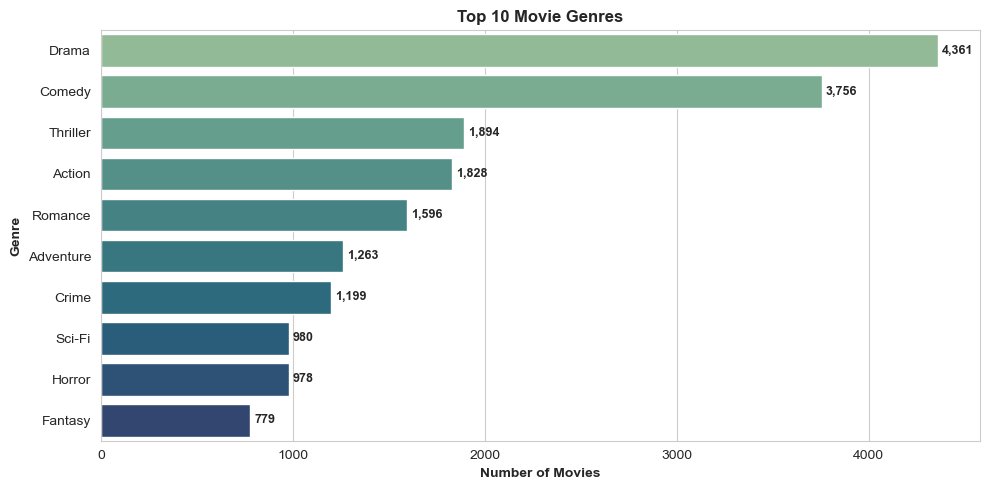

In [14]:
# Split genres
genre_series = movies["genres"].str.split("|").explode()

# Remove missing genre category
genre_series = genre_series[genre_series != "(no genres listed)"]

# Genre counts
genre_counts = genre_series.value_counts().head(10)

plt.figure(figsize=(10, 5))

ax = sns.barplot(x=genre_counts.values, y=genre_counts.index, palette="crest")

# Add data labels
for i, value in enumerate(genre_counts.values):
    ax.text(value + 20, i, f"{value:,}", va="center", fontsize=9, fontweight="bold")

plt.title("Top 10 Movie Genres", fontsize=12, fontweight="bold")
plt.xlabel("Number of Movies", fontsize=10, fontweight="bold")
plt.ylabel("Genre", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

Drama genre is most frequent with a total 4361 movies which is followed by Comedy genre with 3756 movies, while other genres were much less popular.

## **5. Content-Based Recommendation**

### **5.1 Combine Genres and Tags**

In [15]:
# Combine tags for each movie
movie_tags = (
    tags
    .groupby("movieId")["tag"]
    .apply(lambda x: " ".join(x.astype(str)))
    .reset_index()
)

# Rename tag column
movie_tags = movie_tags.rename(columns={"tag": "combined_tags"})

# Merge movies with tags
content_df = movies.merge(movie_tags, on="movieId", how="left")

# Fill missing tags
content_df["combined_tags"] = content_df["combined_tags"].fillna("")

# Create combined content text
content_df["content_features"] = (
    content_df["genres_clean"] + " " + content_df["combined_tags"]
)

# Preview content data
display(content_df[["movieId", "title", "genres_clean", "combined_tags", "content_features"]].head())

,movieId,title,genres_clean,combined_tags,content_features
0,1,Toy Story (1995),Adventure Animation Children Comedy Fantasy,pixar pixar fun,Adventure Animation Children Comedy Fantasy pi...
1,2,Jumanji (1995),Adventure Children Fantasy,fantasy magic board game Robin Williams game,Adventure Children Fantasy fantasy magic board...
2,3,Grumpier Old Men (1995),Comedy Romance,moldy old,Comedy Romance moldy old
3,4,Waiting to Exhale (1995),Comedy Drama Romance,,Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy,pregnancy remake,Comedy pregnancy remake


Genres and Tags are combined to create content-based features to perform content-based filtering.

### **5.2 TF-IDF Vectorisation**

In [16]:
# Initialise TF-IDF vectorizer
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)

# Fit and transform content features
tfidf_matrix = tfidf.fit_transform(content_df["content_features"])

# Check matrix shape
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of movies:", content_df.shape[0])

TF-IDF matrix shape: (9742, 1675)
Number of movies: 9742


From the features numeric feature columns are derived through TF-IDF vectorizer.

### **5.3 Cosine Similarity Matrix**

In [17]:
# Compute cosine similarity
content_similarity = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Convert to dataframe
content_similarity_df = pd.DataFrame(
    content_similarity,
    index=content_df["title"],
    columns=content_df["title"]
)

# Preview similarity matrix
display(content_similarity_df.iloc[:5, :5])

title,Toy Story (1995),Jumanji (1995),Grumpier Old Men (1995),Waiting to Exhale (1995),Father of the Bride Part II (1995)
title,,,,,
Toy Story (1995),1.000000,0.088077,0.013492,0.048353,0.016330
Jumanji (1995),0.088077,1.000000,0.000000,0.000000,0.000000
Grumpier Old Men (1995),0.013492,0.000000,1.000000,0.218274,0.024022
Waiting to Exhale (1995),0.048353,0.000000,0.218274,1.000000,0.086093
Father of the Bride Part II (1995),0.016330,0.000000,0.024022,0.086093,1.000000


Cosine similarity matrix is created on that numeric feature columns which is displayed as indexed dataframe.

### **5.4 Content-Based Recommendation Function**

In [18]:
# Define recommendation function
def recommend_similar_movies(movie_title, similarity_df, n=10):
    if movie_title not in similarity_df.index:
        return f"Movie '{movie_title}' not found in dataset."
    
    similar_scores = similarity_df[movie_title].sort_values(ascending=False)
    similar_scores = similar_scores.drop(movie_title)
    
    recommendations = similar_scores.head(n).reset_index()
    recommendations.columns = ["Recommended Movie", "Similarity Score"]
    
    return recommendations

In [19]:
# Test recommendation
test_movie = "Toy Story (1995)"

content_recommendations = recommend_similar_movies(
    movie_title=test_movie,
    similarity_df=content_similarity_df,
    n=10
)

display(content_recommendations)

,Recommended Movie,Similarity Score
0,"Bug's Life, A (1998)",0.862225
1,Toy Story 2 (1999),0.644038
2,Guardians of the Galaxy 2 (2017),0.367650
3,"Emperor's New Groove, The (2000)",0.357912
4,"Wild, The (2006)",0.357912
5,"Tale of Despereaux, The (2008)",0.357912
6,"Adventures of Rocky and Bullwinkle, The (2000)",0.357912
7,"Monsters, Inc. (2001)",0.357912
8,The Good Dinosaur (2015),0.357912
9,Antz (1998),0.357912


Based on the similarity score a list of movie recommendation is made for a query movie, which are displayed with movie title and similarity score.

## **6. User Rating-Based Recommendation**

### **6.1 Create User-Movie Rating Matrix**

In [20]:
# Create user-movie matrix
user_movie_matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

# Check matrix shape and sparsity
total_cells = user_movie_matrix.shape[0] * user_movie_matrix.shape[1]
missing_cells = user_movie_matrix.isnull().sum().sum()
sparsity = (missing_cells / total_cells) * 100

print("User-movie matrix shape:", user_movie_matrix.shape)
print("Sparsity percentage:", round(sparsity, 2))

display(user_movie_matrix.head())

User-movie matrix shape: (610, 9724)
Sparsity percentage: 98.3


movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In case of user-rating based recommendation the user-movie rating matrix is first created, where most ratings were found to be missing as there are much less number of users than the number of movies and users have rated only a few movies.

### **6.2 Fill Missing Ratings**

In [21]:
# Fill missing ratings with 0 for similarity calculation
user_movie_filled = user_movie_matrix.fillna(0)

# Preview filled matrix
display(user_movie_filled.head())

print("Filled matrix shape:", user_movie_filled.shape)

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Filled matrix shape: (610, 9724)


These missing rating are filled with zero value for calculating the user similarity matrix.

### **6.3 Calculate User Similarity**

In [22]:
# Calculate cosine similarity between users
user_similarity = cosine_similarity(user_movie_filled)

# Convert to dataframe
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_movie_filled.index,
    columns=user_movie_filled.index
)

# Preview similarity matrix
display(user_similarity_df.iloc[:5, :5])

userId,1,2,3,4,5
userId,,,,,
1,1.000000,0.027283,0.059720,0.194395,0.129080
2,0.027283,1.000000,0.000000,0.003726,0.016614
3,0.059720,0.000000,1.000000,0.002251,0.005020
4,0.194395,0.003726,0.002251,1.000000,0.128659
5,0.129080,0.016614,0.005020,0.128659,1.000000


The calculated cosine similarity among users in terms of given ratings to same movies are presented in dataframe.

### **6.4 User-Based Recommendation Function**

In [23]:
# Define user-based recommendation function
def recommend_movies_for_user(user_id, user_movie_matrix, user_similarity_df, movies_df, n=10):
    if user_id not in user_movie_matrix.index:
        return f"User {user_id} not found in dataset."
    
    similar_users = user_similarity_df[user_id].sort_values(ascending=False)
    similar_users = similar_users.drop(user_id)
    
    top_similar_users = similar_users.head(10).index
    
    similar_user_ratings = user_movie_matrix.loc[top_similar_users]
    mean_ratings = similar_user_ratings.mean().sort_values(ascending=False)
    
    movies_seen = user_movie_matrix.loc[user_id].dropna().index
    recommendations = mean_ratings.drop(index=movies_seen, errors="ignore").head(n)
    
    recommendation_df = recommendations.reset_index()
    recommendation_df.columns = ["movieId", "Predicted Rating Score"]
    
    recommendation_df = recommendation_df.merge(
        movies_df[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )
    
    return recommendation_df[["title", "genres", "Predicted Rating Score"]]

In [24]:
# Test recommendation for one user
test_user = 1

user_recommendations = recommend_movies_for_user(
    user_id=test_user,
    user_movie_matrix=user_movie_matrix,
    user_similarity_df=user_similarity_df,
    movies_df=movies,
    n=10
)

display(user_recommendations)

,title,genres,Predicted Rating Score
0,"Sweet Hereafter, The (1997)",Drama,5.0
1,Little Big Man (1970),Western,5.0
2,Twin Peaks: Fire Walk with Me (1992),Crime|Drama|Mystery|Thriller,5.0
3,Five Easy Pieces (1970),Drama,5.0
4,"Trial, The (Procès, Le) (1962)",Drama,5.0
5,Papillon (1973),Crime|Drama,5.0
6,"Last Picture Show, The (1971)",Drama,5.0
7,"Fisher King, The (1991)",Comedy|Drama|Fantasy|Romance,5.0
8,Tremors (1990),Comedy|Horror|Sci-Fi,5.0
9,"River Runs Through It, A (1992)",Drama,5.0


In above, the recommended movies for a user is obtained by the similarity matrix where top 10 movies with highest rating scores are displayed. 

## **7. Improved User-Based Recommendation**

### **7.1 Add Rating Count Filter**

In [25]:
# Define improved recommendation function
def recommend_movies_for_user_filtered(user_id, user_movie_matrix, user_similarity_df, movies_df, n=10, min_ratings=5):
    if user_id not in user_movie_matrix.index:
        return f"User {user_id} not found in dataset."
    
    similar_users = user_similarity_df[user_id].sort_values(ascending=False)
    similar_users = similar_users.drop(user_id)
    top_similar_users = similar_users.head(20).index
    
    similar_user_ratings = user_movie_matrix.loc[top_similar_users]
    
    mean_ratings = similar_user_ratings.mean()
    rating_counts = similar_user_ratings.count()
    
    recommendation_scores = pd.DataFrame({
        "Predicted Rating Score": mean_ratings,
        "Similar User Rating Count": rating_counts
    })
    
    recommendation_scores = recommendation_scores[
        recommendation_scores["Similar User Rating Count"] >= min_ratings
    ]
    
    movies_seen = user_movie_matrix.loc[user_id].dropna().index
    
    recommendations = (
        recommendation_scores
        .drop(index=movies_seen, errors="ignore")
        .sort_values("Predicted Rating Score", ascending=False)
        .head(n)
        .reset_index()
    )
    
    recommendations = recommendations.merge(movies_df[["movieId", "title", "genres"]],
                                            on="movieId", how="left")
    
    return recommendations[["title", "genres", "Predicted Rating Score", "Similar User Rating Count"]]

In [26]:
# Test improved user-based recommendations
filtered_user_recommendations = recommend_movies_for_user_filtered(
    user_id=1,
    user_movie_matrix=user_movie_matrix,
    user_similarity_df=user_similarity_df,
    movies_df=movies,
    n=10,
    min_ratings=5
)

display(filtered_user_recommendations)

,title,genres,Predicted Rating Score,Similar User Rating Count
0,12 Angry Men (1957),Drama,4.800000,5
1,Lawrence of Arabia (1962),Adventure|Drama|War,4.750000,6
2,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.642857,7
3,"Godfather, The (1972)",Crime|Drama,4.625000,16
4,Jaws (1975),Action|Horror,4.625000,16
5,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.550000,10
6,Brazil (1985),Fantasy|Sci-Fi,4.500000,7
7,Pi (1998),Drama|Sci-Fi|Thriller,4.500000,7
8,"Shawshank Redemption, The (1994)",Crime|Drama,4.454545,11
9,One Flew Over the Cuckoo's Nest (1975),Drama,4.454545,11


In improved user-based recommendation a rating-count filter is added to filter movies rated by similar users where average rating is calculated for movies which are rated by at least 5 similar users to improve the reliablity. The top 10 movie recommendations are made as ranked by predicted rating score.

## **8. Hybrid Recommendation System**

In [27]:
# Define hybrid recommendation function
def hybrid_recommendation(user_id, favourite_movie, user_movie_matrix, user_similarity_df,
                          content_similarity_df, movies_df, n=10, min_ratings=5):
    
    # Get user-based recommendations
    user_recs = recommend_movies_for_user_filtered(
        user_id=user_id,
        user_movie_matrix=user_movie_matrix,
        user_similarity_df=user_similarity_df,
        movies_df=movies_df,
        n=50,
        min_ratings=min_ratings
    )
    
    # Check valid output
    if isinstance(user_recs, str):
        return user_recs
    
    if favourite_movie not in content_similarity_df.index:
        return f"Movie '{favourite_movie}' not found in content similarity matrix."
    
    # Get content similarity scores
    content_scores = (
        content_similarity_df[favourite_movie]
        .reset_index()
    )
    
    content_scores.columns = ["title", "Content Similarity Score"]
    
    # Merge user and content scores
    hybrid_df = user_recs.merge(content_scores, on="title", how="left")
    
    # Fill missing similarity scores
    hybrid_df["Content Similarity Score"] = hybrid_df["Content Similarity Score"].fillna(0)
    
    # Normalise predicted rating
    hybrid_df["Rating Score Normalised"] = hybrid_df["Predicted Rating Score"] / 5
    
    # Calculate hybrid score
    hybrid_df["Hybrid Score"] = (
        0.6 * hybrid_df["Rating Score Normalised"] +
        0.4 * hybrid_df["Content Similarity Score"]
    )
    
    # Sort recommendations
    hybrid_df = hybrid_df.sort_values("Hybrid Score", ascending=False).head(n)
    
    return hybrid_df[[
        "title",
        "genres",
        "Predicted Rating Score",
        "Similar User Rating Count",
        "Content Similarity Score",
        "Hybrid Score"
    ]]

In [28]:
# Test hybrid recommendation
hybrid_recs = hybrid_recommendation(
    user_id=1,
    favourite_movie="Toy Story (1995)",
    user_movie_matrix=user_movie_matrix,
    user_similarity_df=user_similarity_df,
    content_similarity_df=content_similarity_df,
    movies_df=movies,
    n=10,
    min_ratings=5
)

display(hybrid_recs)

,title,genres,Predicted Rating Score,Similar User Rating Count,Content Similarity Score,Hybrid Score
5,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.550000,10,0.097159,0.584864
1,Lawrence of Arabia (1962),Adventure|Drama|War,4.750000,6,0.031281,0.582512
6,Brazil (1985),Fantasy|Sci-Fi,4.500000,7,0.104356,0.581742
0,12 Angry Men (1957),Drama,4.800000,5,0.000000,0.576000
2,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.642857,7,0.029865,0.569089
49,Wallace & Gromit: The Wrong Trousers (1993),Animation|Children|Comedy|Crime,4.187500,8,0.146468,0.561087
19,"Lord of the Rings: The Return of the King, The...",Action|Adventure|Drama|Fantasy,4.357143,7,0.088354,0.558199
4,Jaws (1975),Action|Horror,4.625000,16,0.000000,0.555000
3,"Godfather, The (1972)",Crime|Drama,4.625000,16,0.000000,0.555000
38,Pirates of the Caribbean: The Curse of the Bla...,Action|Adventure|Comedy|Fantasy,4.214286,7,0.123183,0.554988


The recommendation is further customised to make a hybrid recommendation system which combines both collaborative (preferred movies by similar users) and content-based filtering (similar movies to a movie) with a hybrid score where 60% weightage is given to user preference and 40% preference is given to content similarity. The final ranked recommendations of 10 movies provides a more balanced and personalised recommendations.

## **9. Recommendation Comparison**

In [29]:
# Compare outputs from three approaches
print("Content-Based Recommendations:")
display(content_recommendations)

print("User-Based Recommendations:")
display(filtered_user_recommendations)

print("Hybrid Recommendations:")
display(hybrid_recs)

Content-Based Recommendations:


,Recommended Movie,Similarity Score
0,"Bug's Life, A (1998)",0.862225
1,Toy Story 2 (1999),0.644038
2,Guardians of the Galaxy 2 (2017),0.367650
3,"Emperor's New Groove, The (2000)",0.357912
4,"Wild, The (2006)",0.357912
5,"Tale of Despereaux, The (2008)",0.357912
6,"Adventures of Rocky and Bullwinkle, The (2000)",0.357912
7,"Monsters, Inc. (2001)",0.357912
8,The Good Dinosaur (2015),0.357912
9,Antz (1998),0.357912


User-Based Recommendations:


,title,genres,Predicted Rating Score,Similar User Rating Count
0,12 Angry Men (1957),Drama,4.800000,5
1,Lawrence of Arabia (1962),Adventure|Drama|War,4.750000,6
2,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.642857,7
3,"Godfather, The (1972)",Crime|Drama,4.625000,16
4,Jaws (1975),Action|Horror,4.625000,16
5,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.550000,10
6,Brazil (1985),Fantasy|Sci-Fi,4.500000,7
7,Pi (1998),Drama|Sci-Fi|Thriller,4.500000,7
8,"Shawshank Redemption, The (1994)",Crime|Drama,4.454545,11
9,One Flew Over the Cuckoo's Nest (1975),Drama,4.454545,11


Hybrid Recommendations:


,title,genres,Predicted Rating Score,Similar User Rating Count,Content Similarity Score,Hybrid Score
5,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.550000,10,0.097159,0.584864
1,Lawrence of Arabia (1962),Adventure|Drama|War,4.750000,6,0.031281,0.582512
6,Brazil (1985),Fantasy|Sci-Fi,4.500000,7,0.104356,0.581742
0,12 Angry Men (1957),Drama,4.800000,5,0.000000,0.576000
2,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.642857,7,0.029865,0.569089
49,Wallace & Gromit: The Wrong Trousers (1993),Animation|Children|Comedy|Crime,4.187500,8,0.146468,0.561087
19,"Lord of the Rings: The Return of the King, The...",Action|Adventure|Drama|Fantasy,4.357143,7,0.088354,0.558199
4,Jaws (1975),Action|Horror,4.625000,16,0.000000,0.555000
3,"Godfather, The (1972)",Crime|Drama,4.625000,16,0.000000,0.555000
38,Pirates of the Caribbean: The Curse of the Bla...,Action|Adventure|Comedy|Fantasy,4.214286,7,0.123183,0.554988


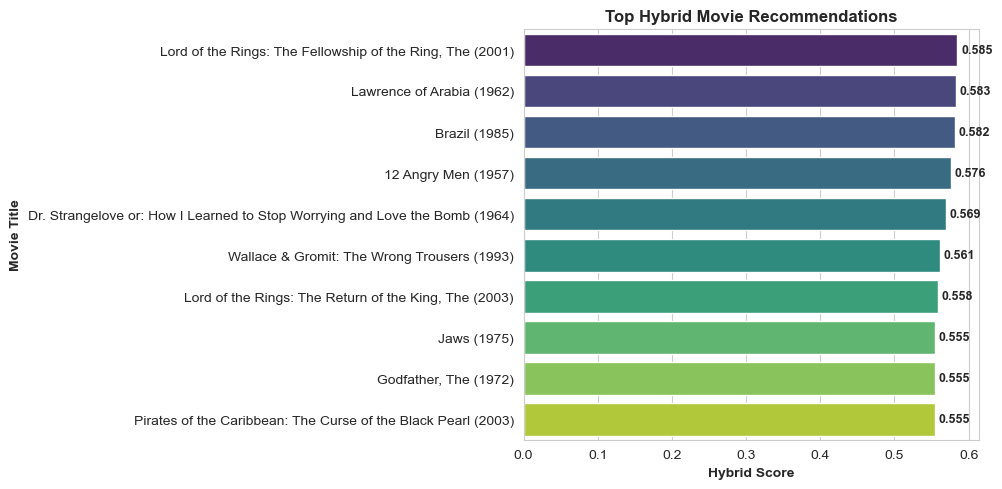

In [30]:
# Plot hybrid scores
plt.figure(figsize=(10, 5))

ax = sns.barplot(data=hybrid_recs, x="Hybrid Score", y="title", palette="viridis")

for i, value in enumerate(hybrid_recs["Hybrid Score"]):
    ax.text(value + 0.005, i, f"{value:.3f}", va="center", fontsize=9, fontweight="bold")

plt.title("Top Hybrid Movie Recommendations", fontsize=12, fontweight="bold")
plt.xlabel("Hybrid Score", fontsize=10, fontweight="bold")
plt.ylabel("Movie Title", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

The example outputs illustrate how content, collaborative, and hybrid scores behave for a selected user and film. They do not establish comparative quality. The held-out evaluation below provides that comparison and shows that the simple popularity baseline is strongest under this sparse, one-item protocol; the original hybrid should therefore be treated as a demonstration rather than a validated improvement.

## 10. Offline ranking evaluation

### Protocol

- Relevant item: a rating of at least 4.0.
- Eligible users: at least 10 total ratings and at least two relevant ratings.
- Holdout: each eligible user's most recent relevant interaction.
- Training: all remaining ratings; the held-out row is removed before user similarity and popularity are calculated.
- Ranking: recommend 10 unseen movies per user.
- Metrics: macro-averaged Precision@10, Recall@10, NDCG@10, and HitRate@10 across 608 eligible users.

This leave-one-positive-out protocol makes Recall@10 and HitRate@10 numerically equal, while Precision@10 is one tenth of the hit rate. Item metadata is allowed for content features, but held-out ratings are not used for collaborative fitting or user-profile construction.


In [ ]:
# Import reusable ranking metrics from the repository utility.
import sys
from pathlib import Path

repo_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.recommender_eval import evaluate_rankings


In [ ]:
# Timestamp-aware leave-one-positive-out split
positive_ratings = ratings[ratings["rating"] >= 4.0].sort_values("timestamp")
rating_counts = ratings.groupby("userId").size()
positive_counts = positive_ratings.groupby("userId").size()
eligible_users = rating_counts[rating_counts >= 10].index.intersection(
    positive_counts[positive_counts >= 2].index
)

holdout = positive_ratings[positive_ratings["userId"].isin(eligible_users)].groupby("userId").tail(1)
evaluation_train = ratings.drop(index=holdout.index)
evaluation_users = np.sort(eligible_users.to_numpy())
evaluation_items = np.sort(movies["movieId"].unique())
user_index = {user_id: index for index, user_id in enumerate(evaluation_users)}
item_index = {movie_id: index for index, movie_id in enumerate(evaluation_items)}

train_matrix = np.zeros((len(evaluation_users), len(evaluation_items)), dtype=np.float32)
observed_matrix = np.zeros_like(train_matrix)
for row in evaluation_train[evaluation_train["userId"].isin(evaluation_users)].itertuples():
    column = item_index.get(row.movieId)
    if column is not None:
        train_matrix[user_index[row.userId], column] = row.rating
        observed_matrix[user_index[row.userId], column] = 1.0

relevant_by_user = {row.userId: {row.movieId} for row in holdout.itertuples()}
print(f"Eligible users: {len(evaluation_users)}")


In [ ]:
# Popularity, user-based collaborative, content-profile, and hybrid score matrices
evaluation_similarity = cosine_similarity(train_matrix)
np.fill_diagonal(evaluation_similarity, 0.0)
weighted_sum = evaluation_similarity @ train_matrix
similarity_mass = np.abs(evaluation_similarity) @ observed_matrix
collaborative_scores = np.divide(
    weighted_sum,
    similarity_mass,
    out=np.zeros_like(weighted_sum),
    where=similarity_mass > 0,
)

evaluation_tags = tags.groupby("movieId")["tag"].apply(lambda values: " ".join(values.astype(str))).rename("tags")
evaluation_metadata = movies[["movieId", "genres"]].merge(evaluation_tags, on="movieId", how="left").fillna({"tags": ""})
evaluation_metadata["text"] = evaluation_metadata["genres"].str.replace("|", " ", regex=False) + " " + evaluation_metadata["tags"]
evaluation_tfidf = TfidfVectorizer(stop_words="english", max_features=5000).fit_transform(
    evaluation_metadata.set_index("movieId").reindex(evaluation_items)["text"].fillna("")
)

content_profile_scores = np.zeros_like(train_matrix)
for row_index, user_id in enumerate(evaluation_users):
    liked = evaluation_train[
        (evaluation_train["userId"] == user_id) & (evaluation_train["rating"] >= 4.0)
    ]["movieId"].map(item_index).dropna().astype(int).tolist()
    if liked:
        profile = np.asarray(evaluation_tfidf[liked].mean(axis=0))
        content_profile_scores[row_index] = cosine_similarity(profile, evaluation_tfidf).ravel()

popularity_vector = evaluation_train[evaluation_train["rating"] >= 4.0].groupby("movieId").size().reindex(
    evaluation_items, fill_value=0
).to_numpy(dtype=np.float32)
popularity_scores = np.tile(popularity_vector, (len(evaluation_users), 1))

def row_minmax(values):
    minimum = values.min(axis=1, keepdims=True)
    maximum = values.max(axis=1, keepdims=True)
    return np.divide(values - minimum, maximum - minimum, out=np.zeros_like(values), where=(maximum - minimum) > 0)

hybrid_evaluation_scores = 0.6 * row_minmax(collaborative_scores) + 0.4 * row_minmax(content_profile_scores)


In [ ]:
# Rank unseen movies and evaluate each approach at K=10
evaluation_rows = []
for model_name, score_matrix in {
    "Popularity": popularity_scores,
    "Content": content_profile_scores,
    "Collaborative": collaborative_scores,
    "Hybrid": hybrid_evaluation_scores,
}.items():
    recommendations = {}
    for row_index, user_id in enumerate(evaluation_users):
        scores = score_matrix[row_index].copy()
        scores[observed_matrix[row_index] > 0] = -np.inf
        top_indices = np.argpartition(scores, -10)[-10:]
        top_indices = top_indices[np.argsort(scores[top_indices])[::-1]]
        recommendations[user_id] = evaluation_items[top_indices].tolist()
    evaluation_rows.append({"Model": model_name, **evaluate_rankings(recommendations, relevant_by_user, k=10)})

ranking_results = pd.DataFrame(evaluation_rows)
display(ranking_results.round(4))


           Model  Precision@K  Recall@K  NDCG@K  HitRate@K  Eligible users
0     Popularity       0.0046     0.0461   0.0267     0.0461           608.0
1        Content       0.0008     0.0082   0.0034     0.0082           608.0
2  Collaborative       0.0000     0.0000   0.0000     0.0000           608.0
3         Hybrid       0.0002     0.0016   0.0016     0.0016           608.0


### Evaluation interpretation

The popularity baseline has the best ranking metrics in this protocol, although absolute recall is low for every approach. The original user-neighborhood method is especially brittle under sparse holdout evaluation: high predicted ratings for niche items do not recover the latest relevant item. Adding content similarity to that score does not overcome the weakness. These results do not support a claim that the hybrid outperforms the baseline; they instead identify sparsity, candidate generation, and score calibration as priorities for future work.

## Limitations

- MovieLens is an offline benchmark; ranking metrics do not measure satisfaction or causal impact.
- A rating threshold of 4.0 is only a proxy for relevance.
- One held-out item per user produces a high-variance estimate and makes Recall@10 equal HitRate@10.
- Content features are limited to genres and user tags; the user-based method has no learned latent factors.
- Cold-start users and new items remain unresolved.

## Conclusion

The notebook demonstrates TF-IDF content similarity, user-based collaborative filtering, and score-level hybridization. Held-out evaluation changes the interpretation of the original example: the simple popularity baseline is strongest, and the hybrid is a prototype rather than a validated improvement. This is a useful analytical result and a clear basis for testing matrix-factorization or implicit-feedback methods next.
